In [252]:
from random import uniform, seed
from math import log
import math
import numpy as np
import matplotlib.pyplot as plt

In [253]:
# Random number generator (Box-Muller, polar form)
def gaussian(mu, sigma, n):
    g = []
    while len(g) < n:
        u1 = uniform(-1, 1)
        u2 = uniform(-1, 1)
        s = u1 * u1 + u2 * u2
        if s > 0 and s < 1:
            k = (-2 * log(s) / s) ** 0.5
            g.append(mu + sigma * u1 * k)
            if len(g) < n:
                g.append(mu + sigma * u2 * k)
    return g

In [254]:
# Train / test split
def split_data(class_points, train_n=8000):
    return class_points[:train_n], class_points[train_n:]

In [255]:
# MLE of the mean
def estimate_mean(train):
    n = len(train)
    return [sum(p[0] for p in train) / n, sum(p[1] for p in train) / n]

In [256]:
# Gaussian log-probability
def gaussian_probability(point, mu, covariance):
    d = 2
    diff = [point[0] - mu[0], point[1] - mu[1]]
    C = covariance
    determinant = C[0][0] * C[1][1] - C[0][1] * C[1][0]
    inverse_C = [
        [C[1][1] / determinant, -C[0][1] / determinant],
        [-C[1][0] / determinant, C[0][0] / determinant],
    ]
    temp = [
        inverse_C[0][0] * diff[0] + inverse_C[0][1] * diff[1],
        inverse_C[1][0] * diff[0] + inverse_C[1][1] * diff[1],
    ]
    quadratic = diff[0] * temp[0] + diff[1] * temp[1]
    return (
        -(d / 2) * math.log(2 * math.pi)
        - 0.5 * math.log(determinant)
        - 0.5 * quadratic
    )

In [257]:

# Classify the test data
def classify(test_classes, mus, covs):
    test_data = []
    for label, pts in enumerate(test_classes, start=1):
        test_data += [(p, label) for p in pts]
    actual, predicted = [], []
    for point, actual_class in test_data:
        probs = [gaussian_probability(point, mus[i], covs[i]) for i in range(3)]
        predicted.append(probs.index(max(probs)) + 1)
        actual.append(actual_class)
    return test_data, actual, predicted

In [258]:
# Print results
def print_results(train_n, test_classes, test_data, actual, predicted):
    print("Training points per class:", train_n)
    print("Testing points per class:", len(test_classes[0]))
    print("Total test points:", len(test_data))
 
    correct = sum(a == p for a, p in zip(actual, predicted))
    accuracy = correct / len(actual)
    print("\nCorrect predictions:", correct)
    print("Total predictions:", len(actual))
    print("Accuracy:", accuracy)
    print("Accuracy (%):", accuracy * 100)

In [259]:
# Discriminant function + decision boundary plot
def discriminant(x, y, mu, covariance):
    det = covariance[0][0] * covariance[1][1] - covariance[0][1] * covariance[1][0]
    inv = [
        [covariance[1][1] / det, -covariance[0][1] / det],
        [-covariance[1][0] / det, covariance[0][0] / det],
    ]
    dx, dy = x - mu[0], y - mu[1]
    quadratic = dx * (inv[0][0] * dx + inv[0][1] * dy) + dy * (inv[1][0] * dx + inv[1][1] * dy)
    return -0.5 * math.log(det) - 0.5 * quadratic


def plot_boundaries(test_classes, mus, covs, lo, hi,tit):
    gx, gy = np.meshgrid(np.linspace(lo, hi, 500), np.linspace(lo, hi, 500))
    G = [discriminant(gx, gy, mus[i], covs[i]) for i in range(3)]
    decision = np.argmax(np.array(G), axis=0)

    plt.figure(figsize=(8, 6))
    for i, pts in enumerate(test_classes, start=1):
        plt.scatter([p[0] for p in pts], [p[1] for p in pts], s=5, alpha=0.5, label=f"Class {i}")
    plt.contour(gx, gy, decision, levels=[0.5, 1.5], linewidths=2)
    for mu in mus:
        plt.scatter(mu[0], mu[1], marker="x", s=100,
            linewidths=3, color="black")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title(tit)
    plt.legend()
    plt.grid(True)
    plt.show()

In [260]:
# Confusion matrix
def print_confusion_matrix(actual, predicted):
    cm = [[0] * 3 for _ in range(3)]
    for a, p in zip(actual, predicted):
        cm[a - 1][p - 1] += 1
    print("\nConfusion Matrix:")
    print("              Predicted")
    print("             C1    C2    C3")
    print("Actual C1   ", cm[0])
    print("       C2   ", cm[1])
    print("       C3   ", cm[2])

In [261]:
def plot_roc(test_data, mus, covs, classes=(1, 2, 3)):
    plt.figure(figsize=(8, 6))
    for target in classes:
        k = target - 1
        scores = [gaussian_probability(p, mus[k], covs[k]) for p, _ in test_data]
        is_target = [a == target for _, a in test_data]
        P = sum(is_target)
        N = len(is_target) - P

        # Sweeping the threshold from high to low = walking down the sorted scores
        order = sorted(range(len(scores)), key=lambda i: scores[i], reverse=True)
        tp = fp = 0
        tpr_values, fpr_values = [0.0], [0.0]
        for i in order:
            if is_target[i]:
                tp += 1
            else:
                fp += 1
            tpr_values.append(tp / P)
            fpr_values.append(fp / N)

        auc = sum(
            (fpr_values[i] - fpr_values[i - 1]) * (tpr_values[i] + tpr_values[i - 1]) / 2
            for i in range(1, len(fpr_values))
        )
        plt.plot(fpr_values, tpr_values, linewidth=2, label=f"Class {target} ROC (AUC = {auc:.3f})")

    plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1.5, label="Random System")
    plt.xlabel("False Positive Rate (FPR)")
    plt.ylabel("True Positive Rate (TPR)")
    plt.title("ROC Curves - Each Class vs Non-Target")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True)
    plt.show()

Mean: [2.02655601800276, 3.012996249479939] Sigma^2: 1.0134124696013826 

Mean: [4.002618203857019, 4.987420972284875] Sigma^2: 1.0043813141610065 

Mean: [6.00600675646717, 8.007355906783614] Sigma^2: 1.0074016144469091 

Training points per class: 8000
Testing points per class: 2000
Total test points: 6000

Correct predictions: 5513
Total predictions: 6000
Accuracy: 0.9188333333333333
Accuracy (%): 91.88333333333333


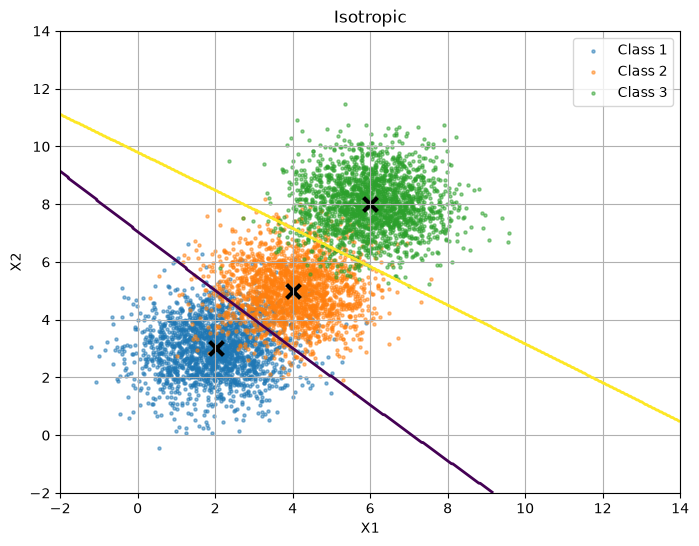


Confusion Matrix:
              Predicted
             C1    C2    C3
Actual C1    [1832, 168, 0]
       C2    [157, 1758, 85]
       C3    [0, 77, 1923]


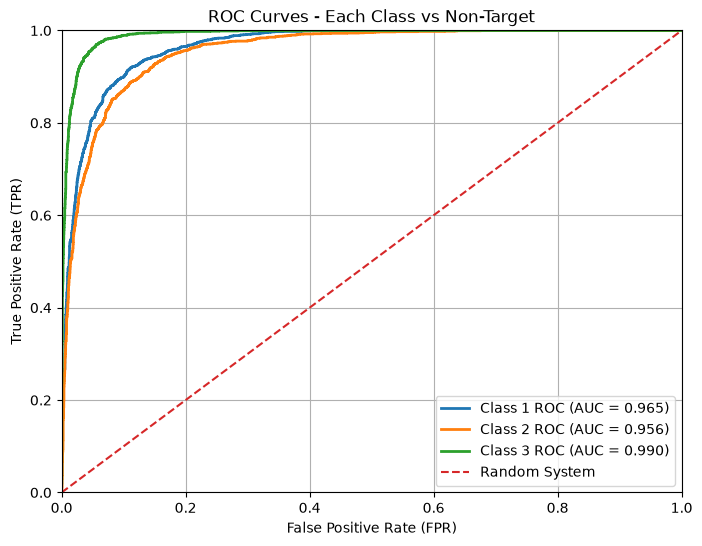

In [262]:

n, train_n = 10000, 8000
sigma = 1 
means = [[2, 3], [4, 5], [6, 8]]             

# DIFFERENT PART 1: data generation (same sigma for X and Y)
classes = []
for m in means:
    X = gaussian(m[0], sigma, n)
    Y = gaussian(m[1], sigma, n)
    classes.append([[X[i], Y[i]] for i in range(n)])

# COMMON: split + mean
splits = [split_data(c, train_n) for c in classes]
train = [s[0] for s in splits]
test = [s[1] for s in splits]
mus = [estimate_mean(t) for t in train]

# DIFFERENT PART 2: covariance MLE (one sigma^2 shared by x and y)
covs = []
for t, mu in zip(train, mus):
    s2 = sum((p[0] - mu[0]) ** 2 + (p[1] - mu[1]) ** 2 for p in t) / (2 * train_n)
    covs.append([[s2, 0], [0, s2]])
    print("Mean:", mu, "Sigma^2:", s2,"\n")

# COMMON: classify, report, plot
test_data, actual, predicted = classify(test, mus, covs)
print_results(train_n, test, test_data, actual, predicted)
plot_boundaries(test, mus, covs, -2, 14,"Isotropic")      
print_confusion_matrix(actual, predicted)
plot_roc(test_data, mus, covs)

Mean: [1.9829305764184466, 2.989777506575379] Sigma_x^2: 0.9856206690650248 Sigma_y^2: 4.082174028448944 

Mean: [3.9858250087033875, 4.995817597420112] Sigma_x^2: 1.011963257060937 Sigma_y^2: 4.189439455428719 

Mean: [6.982664005086746, 8.012892250109125] Sigma_x^2: 1.0052950286473459 Sigma_y^2: 3.9706795468932663 

Training points per class: 8000
Testing points per class: 2000
Total test points: 6000

Correct predictions: 5293
Total predictions: 6000
Accuracy: 0.8821666666666667
Accuracy (%): 88.21666666666667


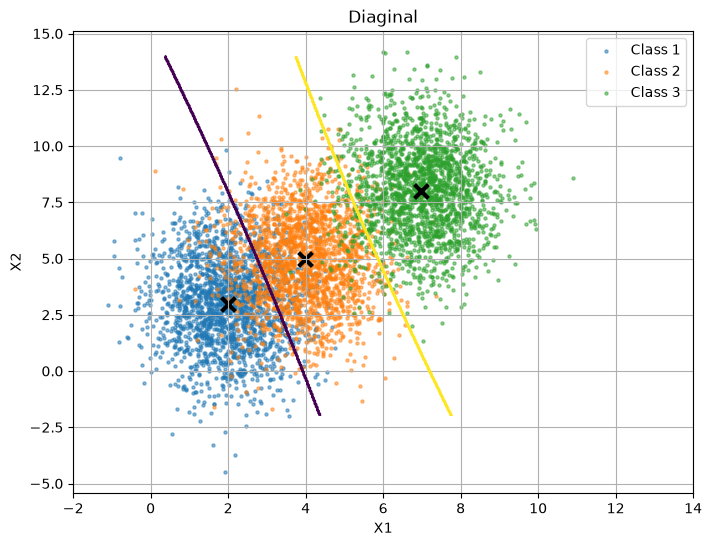


Confusion Matrix:
              Predicted
             C1    C2    C3
Actual C1    [1724, 276, 0]
       C2    [253, 1668, 79]
       C3    [0, 99, 1901]


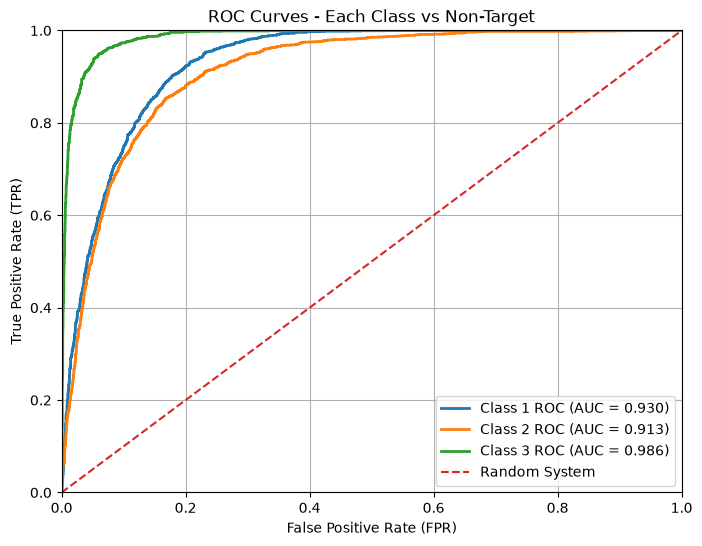

In [263]:

    
n, train_n = 10000, 8000
sigma_x, sigma_y = 1, 2
means = [[2, 3], [4, 5], [7, 8]]

# DIFFERENT PART 1: data generation (independent X, Y with different sigma)
classes = []
for m in means:
    X = gaussian(m[0], sigma_x, n)
    Y = gaussian(m[1], sigma_y, n)
    classes.append([[X[i], Y[i]] for i in range(n)])

# COMMON: split + mean
splits = [split_data(c, train_n) for c in classes]
train = [s[0] for s in splits]
test = [s[1] for s in splits]
mus = [estimate_mean(t) for t in train]

# DIFFERENT PART 2: covariance MLE (diagonal: separate variances, zero off-diagonal)
covs = []
for t, mu in zip(train, mus):
    vx = sum((p[0] - mu[0]) ** 2 for p in t) / train_n
    vy = sum((p[1] - mu[1]) ** 2 for p in t) / train_n
    covs.append([[vx, 0], [0, vy]])
    print("Mean:", mu, "Sigma_x^2:", vx, "Sigma_y^2:", vy,"\n")

# COMMON: classify, report, plot
test_data, actual, predicted = classify(test, mus, covs)
print_results(train_n, test, test_data, actual, predicted)
plot_boundaries(test, mus, covs, -2, 14,"Diaginal")      # DIFFERENT: plot range
print_confusion_matrix(actual, predicted)
plot_roc(test_data, mus, covs)

Mean: [np.float64(0.96899188103142), np.float64(1.9853831338434074)] 
Covariance: [[np.float64(4.0253294543088245), np.float64(1.0349303469893216)], [np.float64(1.0349303469893216), np.float64(1.0319909434976566)]] 

Mean: [np.float64(3.994905654225878), np.float64(4.996677058365708)] 
Covariance: [[np.float64(4.045263783991131), np.float64(1.0263182326766935)], [np.float64(1.0263182326766935), np.float64(1.0028992524024596)]] 

Mean: [np.float64(6.995370051735204), np.float64(8.996603888385424)] 
Covariance: [[np.float64(4.056659261672709), np.float64(0.9946496558694319)], [np.float64(0.9946496558694319), np.float64(0.9882226522799084)]] 

Training points per class: 8000
Testing points per class: 2000
Total test points: 6000

Correct predictions: 5620
Total predictions: 6000
Accuracy: 0.9366666666666666
Accuracy (%): 93.66666666666667


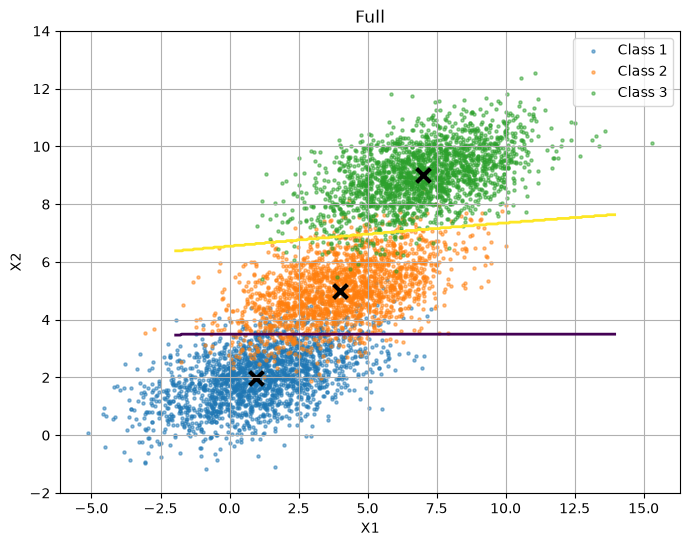


Confusion Matrix:
              Predicted
             C1    C2    C3
Actual C1    [1870, 130, 0]
       C2    [134, 1803, 63]
       C3    [0, 53, 1947]


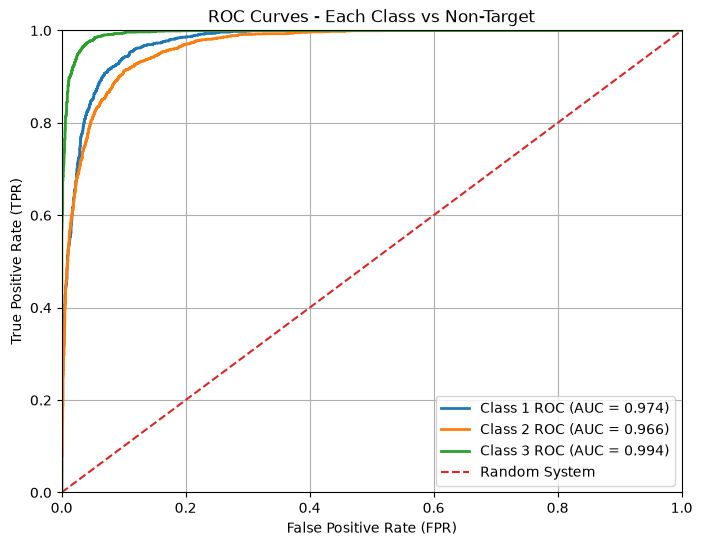

In [264]:

n, train_n = 10000, 8000
covariance = np.array([[4, 1], [1, 1]], dtype=float)
means = [[1, 2], [4, 5], [7, 9]]

# DIFFERENT PART 1: data generation (correlated, using C^(1/2))
eigenvalues, eigenvectors = np.linalg.eigh(covariance)
C_sqrt = (
    (eigenvalues[1] ** 0.5) * np.outer(eigenvectors[:, 1], eigenvectors[:, 1])
    + (eigenvalues[0] ** 0.5) * np.outer(eigenvectors[:, 0], eigenvectors[:, 0])
)
classes = []
for m in means:
    Z1 = gaussian(0, 1, n)
    Z2 = gaussian(0, 1, n)
    pts = []
    for i in range(n):
        Y = np.array(m) + C_sqrt @ np.array([Z1[i], Z2[i]])
        pts.append([Y[0], Y[1]])
    classes.append(pts)

# COMMON: split + mean
splits = [split_data(c, train_n) for c in classes]
train = [s[0] for s in splits]
test = [s[1] for s in splits]
mus = [estimate_mean(t) for t in train]

# DIFFERENT PART 2: covariance MLE (full matrix, includes sigma_xy)
covs = []
for t, mu in zip(train, mus):
    vx = sum((p[0] - mu[0]) ** 2 for p in t) / train_n
    vy = sum((p[1] - mu[1]) ** 2 for p in t) / train_n
    vxy = sum((p[0] - mu[0]) * (p[1] - mu[1]) for p in t) / train_n
    covs.append([[vx, vxy], [vxy, vy]])
    print("Mean:", mu, "\nCovariance:", covs[-1],"\n")

# COMMON: classify, report, plot
test_data, actual, predicted = classify(test, mus, covs)
print_results(train_n, test, test_data, actual, predicted)
plot_boundaries(test, mus, covs, -2, 14,"Full")      # DIFFERENT: plot range
print_confusion_matrix(actual, predicted)
plot_roc(test_data, mus, covs)